Karpathy Micrograd Lecture Content

https://www.youtube.com/watch?v=VMj-3S1tku0

In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import random
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

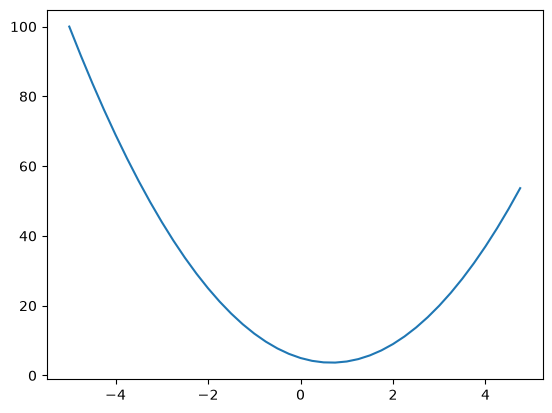

In [4]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
h=0.001
x=3.0
(f(x+h) - f(x))/h

14.00300000000243

In [6]:
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [7]:
h=0.0001

a=2.0
b=-3.0
c=10.0

d1=a*b+c
c+=h
d2=a*b+c

print('d1',d1)
print('d2',d2)
print('slope',(d2-d1)/h)

d1 4.0
d2 4.0001
slope 0.9999999999976694


In [ ]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __sub__(self, other):
        return self + (-1 * other)

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self, ), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    # this is needed for Neuron __call__ sum(wi * xi for wi, xi in zip(self.w, x))
    # because sum starts add 0, it does 0 + Value(), which means other + Value
    # __add__ only handles Value + other
    def __radd__(self, other):
        return self + other
    
    def __rmul__(self, other):
        return self * other

    def __truediv__(self, other):
        return self * other**-1
        
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo=[]
        visited=set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()


In [34]:
a=Value(2.0)
b=Value(4.0)
a-b

Value(data=-2.0)

In [26]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{%s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [10]:
# dL/dd = ?

# 导数公式 (f(x+h)-f(x))/h
# 所以L相对于d的导数就是 ((d+h)*f - d*f)/h
# (d*f + h*f - d*f)/h
# h*f / h = f
# 所以dL/dd = f

# dL/dc = ?
# chain rule: dL/dc = dL/dd * dd/dc = -2.0 * 1.0 = -2.0
# same goes for dL/de = dL/dd * dd/de = -2.0 * 1.0 = -2.0

# dd/dc = ?
# d = e + c
# dd/dc = 1.0
# dd/dd = 1.0

# dL/da = dL/de * de/da = -2.0 * -3.0 = 6.0
# dL/db = dL/de * de/db = -2.0 * 2 = -4.0


In [35]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2 + b; n.label='n'
o = n.tanh(); o.label = 'o'
o.backward()


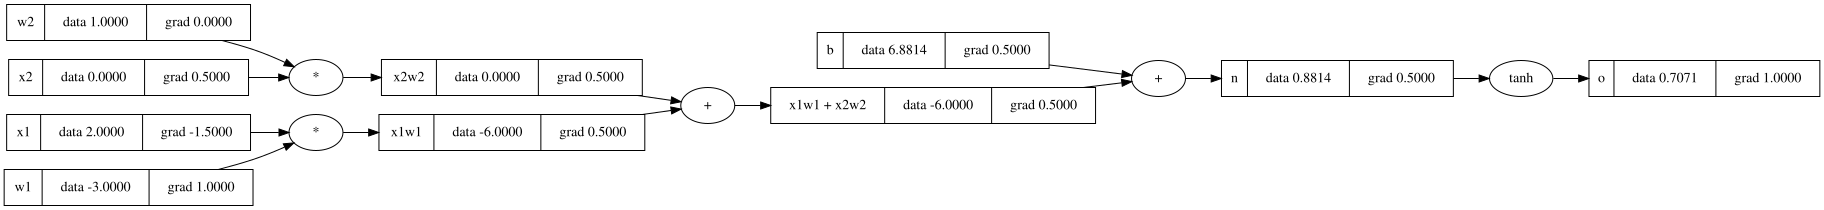

In [36]:
draw_dot(o)

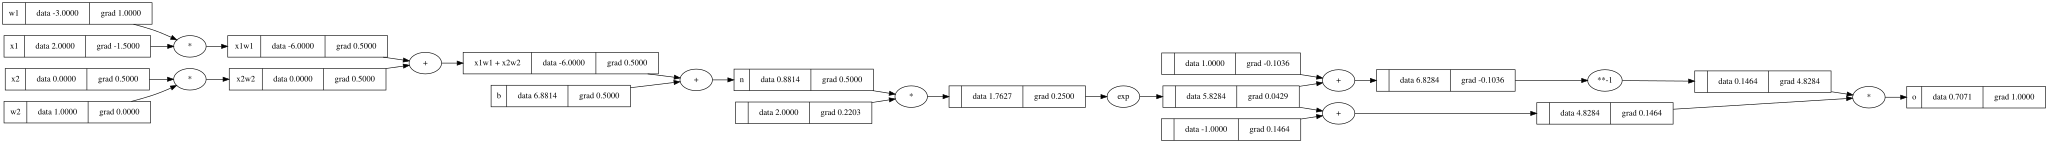

In [37]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label='x1w1 + x2w2'
n = x1w1x2w2 + b; n.label='n'
# ---
e = (2*n).exp()
o = (e - 1) / (e + 1)
# ---
o.label = 'o'
o.backward()
draw_dot(o)


In [15]:
# o=tanh(n)
# do/dn = 1 - tanh(n)**2 = 1 - o**2

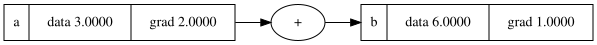

In [16]:
a=Value(3.0,label='a')
b=a+a;b.label='b'
b.backward()
draw_dot(b)

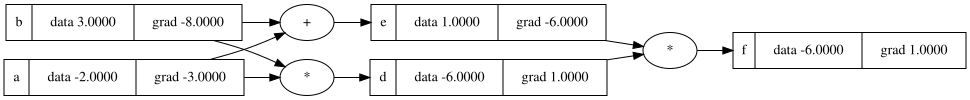

In [ ]:
# 这个案例展示了grad为什么需要累积，不然的话，如果一个变量被多次使用，就会被最后一次使用时的grad给覆盖

a=Value(-2.0,label='a')
b=Value(3.0,label='b')
d=a*b;d.label='d'
e=a+b;e.label='e'
f=d*e;f.label='f'
f.backward()
draw_dot(f)

In [6]:
import torch
import random

In [ ]:


x1 = torch.tensor(2.0, dtype=torch.float64, requires_grad=True);
x2 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True);
w1 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True);
w2 = torch.tensor(1.0, dtype=torch.float64, requires_grad=True);
b = torch.tensor(6.8813735870195432, dtype=torch.float64, requires_grad=True);
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()
print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071067811865476
---
x2 0.49999999999999994
w2 0.0
x1 -1.4999999999999998
w1 0.9999999999999999


In [35]:
class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



In [53]:
x=[2.0,3.0,-1.0]
n=MLP(3,[4,4,1])
n(x)

Value(data=0.7115337854088924)

In [59]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0]

In [60]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss =sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)


0 1.0478399454243125e-10
1 1.0478399451092492e-10
2 1.0478399447991122e-10
3 1.0478399444778416e-10
4 1.0478399441554688e-10
5 1.0478399438596293e-10
6 1.0478399435577618e-10
7 1.0478399432353888e-10
8 1.0478399429251095e-10
9 1.047839942603981e-10
10 1.047839942315309e-10
11 1.0478399420050295e-10
12 1.0478399416839013e-10
13 1.0478399413494352e-10
14 1.0478399410585587e-10
15 1.0478399407374304e-10
16 1.0478399404293552e-10
17 1.0478399401201779e-10
18 1.0478399398173504e-10
19 1.0478399394828843e-10


In [61]:
ypred

[Value(data=0.9999967079986175),
 Value(data=-0.999994553649708),
 Value(data=-0.9999940572814953),
 Value(data=0.9999946177991382)]